# Fraudulent Bitcoin Transaction Detection
**Student number: A0269592L | BT4012 In-class Kaggle Competition 2026**

This notebook regenerates **both submissions selected for the final private leaderboard**: `submission_rankblend_best_decay12.csv` (recorded public ROC AUC **0.95154**) and `submission_best_plus_ordered15.csv` (**0.95184**). It loads the supplied competition data, checks data quality, evaluates chronological holdouts, trains three shared CatBoost models, runs inference and exports both CSV files under their original filenames. Public scores are recorded observations, not independently verified private results.

## Reproduction instructions
Place this notebook in the project root or a direct subfolder. Put `train.csv`, `test.csv`, `sample_submission.csv` and `txs_edgelist.csv` in `data/` under the project root. Restart the kernel and run all cells. No earlier notebook, saved model, prediction file or external dataset is needed. The previously completed CPU run took about 65 minutes; runtime depends on the machine. The export step requires no additional model fitting for the second selection. The notebook creates its own `results/final_submission/` directory.

Install the following dependencies in a Python 3.10 environment. The same text can be saved as the `requirements.txt` required in the GitHub repository:
```text
numpy==1.25.2
pandas==2.0.3
scipy==1.11.1
scikit-learn==1.7.2
catboost==1.2.10
matplotlib==3.7.2
nbformat==5.10.4
ipykernel
notebook
```
GitHub repository: **[ADD REPOSITORY LINK BEFORE SUBMISSION]**.

In [1]:
import os
# Limit numerical-library threads before importing them to avoid CPU oversubscription.
for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[variable] = '4'
from pathlib import Path
from time import perf_counter
import hashlib, json, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, average_precision_score
from catboost import CatBoostClassifier
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/train.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/train.csv').exists(), 'Place the supplied CSV files under data/.'
OUT = ROOT / 'results/final_submission'
OUT.mkdir(parents=True, exist_ok=True)
FEATURES = [f'feat_{i}' for i in range(1, 166)]
SEED = 42
THREADS = 4
CUTOFFS = [18, 20, 22, 28]
HORIZON = 14

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'catboost', 'matplotlib']}
print('Python:', platform.python_version())
print('Package versions:', versions)
assert versions['catboost'] == '1.2.10', 'Use the documented CatBoost version for reproduction.'
input_hashes = {name: sha256(ROOT / 'data' / name) for name in
                ['train.csv', 'test.csv', 'sample_submission.csv', 'txs_edgelist.csv']}
display(pd.Series(input_hashes, name='input SHA256'))

Python: 3.10.11
Package versions: {'numpy': '1.25.2', 'pandas': '2.0.3', 'scipy': '1.11.1', 'scikit-learn': '1.7.2', 'catboost': '1.2.10', 'matplotlib': '3.7.2'}


train.csv                6f7e56883f0aa27147262a0d71954ad64702ca57f16fbf...
test.csv                 ba9aac8a9028e80135d5dce0cb696bd36a8bd86315ff4f...
sample_submission.csv    3dba74ad6151053aa21f366fb9faf6da7393969a0ba6f8...
txs_edgelist.csv         a35053ba68a98e4382cae2ba65b9d9e36b23b6439e02df...
Name: input SHA256, dtype: object

## 1 Data preprocessing and graph inspection
Blank labels denote unknown status. They are excluded from supervised training and validation, never converted to licit labels. IDs are checked for uniqueness and disjointness. The 165 supplied numeric features are retained; `txId`, `index` and `time_step` are excluded from the predictor matrix. Time is used only for splitting and age weights. There are no missing feature values in these inputs, so no imputation is necessary. CatBoost does not require feature scaling.

An edge links an earlier transaction to a transaction spending one of its outputs. The degree diagnostic below uses the supplied graph snapshot. Successor connectivity may be unavailable at transaction arrival. Added graph statistics did not provide a consistent gain in earlier experiments and are excluded from the final model; supplied anonymized aggregate features remain included.

In [2]:
train = pd.read_csv(ROOT / 'data/train.csv')
test = pd.read_csv(ROOT / 'data/test.csv')
sample = pd.read_csv(ROOT / 'data/sample_submission.csv')
edges = pd.read_csv(ROOT / 'data/txs_edgelist.csv')
labels = pd.to_numeric(train['label'], errors='raise')
known = labels.notna()
assert set(labels[known].unique()) == {0, 1}
assert train.txId.is_unique and test.txId.is_unique
assert not set(train.txId).intersection(test.txId)
assert train.time_step.max() < test.time_step.min()
assert test['index'].equals(sample['index']) and sample['index'].is_unique
assert list(sample.columns) == ['index', 'target']
assert all(f in train and f in test for f in FEATURES)
assert np.isfinite(train[FEATURES].to_numpy()).all()
assert np.isfinite(test[FEATURES].to_numpy()).all()
lab = train.loc[known].reset_index(drop=True)
y = lab.label.astype(int).to_numpy()
t = lab.time_step.to_numpy()
X = lab[FEATURES].to_numpy(np.float32)
X_test = test[FEATURES].to_numpy(np.float32)
display(pd.DataFrame({
    'quantity': ['Training transactions', 'Known licit', 'Known illicit', 'Unknown labels',
                 'Illicit share of known labels', 'Test transactions', 'Graph edges'],
    'value': [len(train), int((y == 0).sum()), int(y.sum()), int((~known).sum()),
              float(y.mean()), len(test), len(edges)]}))
source, destination = edges.columns[:2]
in_degree = edges[destination].value_counts()
out_degree = edges[source].value_counts()
degree_diagnostic = pd.DataFrame({'txId': train.txId})
degree_diagnostic['in_degree'] = degree_diagnostic.txId.map(in_degree).fillna(0)
degree_diagnostic['out_degree'] = degree_diagnostic.txId.map(out_degree).fillna(0)
display(degree_diagnostic[['in_degree', 'out_degree']].describe())
print('Training time steps:', train.time_step.min(), '-', train.time_step.max())
print('Test time steps:', test.time_step.min(), '-', test.time_step.max())

,quantity,value
0,Training transactions,141772.000000
1,Known licit,27591.000000
2,Known illicit,3644.000000
3,Unknown labels,110537.000000
4,Illicit share of known labels,0.116664
5,Test transactions,15329.000000
6,Graph edges,234355.000000


,in_degree,out_degree
count,141772.000000,141772.000000
mean,1.151102,1.151102
std,3.568221,1.960910
min,0.000000,0.000000
25%,0.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,284.000000,472.000000


Training time steps: 1 - 35
Test time steps: 36 - 49


## 2 Model definitions and final strategy
All three components use depth 8, learning rate 0.04, L2 leaf regularization 5, seed 42 and binary log loss. The final fits use 1,200 iterations with no early stopping. The components are:

1. Plain CatBoost trained on all known labels with equal weights.
2. Plain CatBoost with age weights `0.5 ** ((cutoff - time_step) / 12)`, retaining older examples with decreasing influence.
3. Ordered CatBoost trained with equal weights, supplying a different boosting procedure.

No class multiplier or resampling is applied in the final model. Earlier weighted models and reduced feature subsets did not consistently improve results. Rank averaging reduces sensitivity to different score scales. If `r` denotes average rank divided by the number of predicted rows, the final score is `0.85*r(0.5*r(plain) + 0.5*r(decay)) + 0.15*r(ordered)`.

For exact historical reproduction the final plain component receives the original pandas float64 features; the decay and Ordered components receive float32 arrays. The first rank blend is rounded to nine decimal places before the outer rank, matching the saved intermediate submission. Scores are valid in [0,1] and optimize ranking; they are **not calibrated probabilities** and should not be thresholded at 0.5 for operational decisions.

Both selected submissions reuse these components. The temporal selection exports `b = 0.5*r(plain) + 0.5*r(decay)` to **nine decimal places**. The Ordered selection exports `0.85*r(b) + 0.15*r(ordered)`, using the temporal CSV's saved precision. Thus the second file needs no additional training. The export cell below verifies both files against their recorded SHA-256 checksums without requiring the historical CSVs to be present.

In [3]:
def parameters(iterations=1200, ordered=False, threads=THREADS):
    p = dict(iterations=iterations, depth=8, learning_rate=0.04, l2_leaf_reg=5,
             loss_function='Logloss', random_seed=SEED, verbose=False,
             allow_writing_files=False, thread_count=threads)
    if ordered:
        p['boosting_type'] = 'Ordered'
    return p

def rank01(values):
    values = np.asarray(values)
    assert values.ndim == 1 and np.isfinite(values).all()
    return rankdata(values, method='average') / len(values)

def blend(plain, decay, ordered, historical_rounding=False):
    temporal = 0.5 * rank01(plain) + 0.5 * rank01(decay)
    if historical_rounding:
        temporal = np.round(temporal, 9)
    return 0.85 * rank01(temporal) + 0.15 * rank01(ordered)

display(pd.Series(parameters(), name='plain and decay parameters'))

iterations                1200
depth                        8
learning_rate             0.04
l2_leaf_reg                  5
loss_function          Logloss
random_seed                 42
verbose                  False
allow_writing_files      False
thread_count                 4
Name: plain and decay parameters, dtype: object

## 3 Chronological prediction validation
For each cutoff, fit only known labels at or before that cutoff. Score known labels in the next 14 steps, capped at step 35. All unknown and validation labels are excluded from fitting. The four cutoffs overlap and their means are descriptive, not independent cross-validation estimates.

This reproduces the historical blend experiment: plain and decay use 1,200 iterations, while Ordered uses **400 iterations for validation** to limit cost. The final Ordered model uses 1,200 iterations. Consequently these metrics validate an analogue of the final strategy, not the exact final training budget. Both ROC AUC and average precision are reported. No test labels are available. The four folds are refitted from scratch here.

Cutoff 18: plain complete
Cutoff 18: decay complete
Cutoff 18 complete in 713.5s
Cutoff 20: plain complete
Cutoff 20: decay complete
Cutoff 20 complete in 683.3s
Cutoff 22: plain complete
Cutoff 22: decay complete
Cutoff 22 complete in 689.8s
Cutoff 28: plain complete
Cutoff 28: decay complete
Cutoff 28 complete in 685.1s


,cutoff,validation_end,model,training_rows,validation_rows,illicit_rows,roc_auc,average_precision
0,18,32,plain,17244,11694,1971,0.853105,0.800490
1,18,32,decay12,17244,11694,1971,0.859758,0.800487
2,18,32,ordered400,17244,11694,1971,0.877685,0.805322
3,18,32,temporal_rank_blend,17244,11694,1971,0.857693,0.801052
4,18,32,final_blend_analogue,17244,11694,1971,0.861167,0.802093
5,20,34,plain,18889,11005,1691,0.779147,0.769574
6,20,34,decay12,18889,11005,1691,0.777101,0.768386
7,20,34,ordered400,18889,11005,1691,0.869884,0.793309
8,20,34,temporal_rank_blend,18889,11005,1691,0.776649,0.769012
9,20,34,final_blend_analogue,18889,11005,1691,0.788408,0.771707


,roc_auc,average_precision
model,,
decay12,0.860305,0.832197
final_blend_analogue,0.863357,0.833053
ordered400,0.887519,0.838497
plain,0.859589,0.831900
temporal_rank_blend,0.859752,0.832100


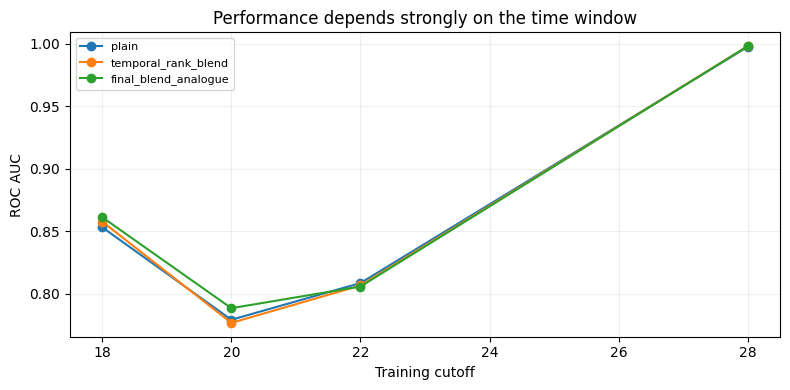

In [4]:
validation_rows = []
for cutoff in CUTOFFS:
    fit = t <= cutoff
    valid = (t > cutoff) & (t <= min(cutoff + HORIZON, 35))
    assert set(y[fit]) == {0, 1} and set(y[valid]) == {0, 1}
    start = perf_counter()
    plain = CatBoostClassifier(**parameters()).fit(
        X[fit], y[fit], sample_weight=np.ones(int(fit.sum())))
    print(f'Cutoff {cutoff}: plain complete', flush=True)
    decay = CatBoostClassifier(**parameters()).fit(
        X[fit], y[fit], sample_weight=0.5 ** ((cutoff - t[fit]) / 12))
    print(f'Cutoff {cutoff}: decay complete', flush=True)
    ordered = CatBoostClassifier(**parameters(400, ordered=True)).fit(X[fit], y[fit])
    p = plain.predict_proba(X[valid])[:, 1]
    d = decay.predict_proba(X[valid])[:, 1]
    o = ordered.predict_proba(X[valid])[:, 1]
    temporal = 0.5 * rank01(p) + 0.5 * rank01(d)
    final = blend(p, d, o)
    for name, pred in [('plain', p), ('decay12', d), ('ordered400', o),
                       ('temporal_rank_blend', temporal), ('final_blend_analogue', final)]:
        validation_rows.append(dict(cutoff=cutoff, validation_end=int(t[valid].max()),
            model=name, training_rows=int(fit.sum()), validation_rows=int(valid.sum()),
            illicit_rows=int(y[valid].sum()), roc_auc=roc_auc_score(y[valid], pred),
            average_precision=average_precision_score(y[valid], pred)))
    print(f'Cutoff {cutoff} complete in {perf_counter() - start:.1f}s', flush=True)
metrics = pd.DataFrame(validation_rows)
metrics.to_csv(OUT / 'validation_metrics.csv', index=False)
display(metrics.round(6))
display(metrics.groupby('model')[['roc_auc', 'average_precision']].mean().round(6))
fig, ax = plt.subplots(figsize=(8, 4))
for name in ['plain', 'temporal_rank_blend', 'final_blend_analogue']:
    part = metrics[metrics.model.eq(name)]
    ax.plot(part.cutoff, part.roc_auc, marker='o', label=name)
ax.set(xlabel='Training cutoff', ylabel='ROC AUC', title='Performance depends strongly on the time window')
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4 Refit the final model on all known labels
Validation labels are now included in training because the held-out competition test set covers later steps 36-49. Hyperparameters and blend weights are fixed before this refit. All 31,235 known labels from steps 1-35 are used. Unknown labels receive no pseudo-labels. Only the supplied data are used.

In [5]:
start = perf_counter()
plain_final = CatBoostClassifier(**parameters(threads=4))
plain_final.fit(lab[FEATURES], y)
plain_test = plain_final.predict_proba(test[FEATURES])[:, 1]
print('Plain model complete', flush=True)
decay_final = CatBoostClassifier(**parameters(threads=16))
decay_final.fit(X, y, sample_weight=0.5 ** ((35 - t) / 12))
decay_test = decay_final.predict_proba(X_test)[:, 1]
print('Decay model complete', flush=True)
ordered_final = CatBoostClassifier(**parameters(ordered=True, threads=12))
ordered_final.fit(X, y)
ordered_test = ordered_final.predict_proba(X_test)[:, 1]
target = blend(plain_test, decay_test, ordered_test, historical_rounding=True)
print(f'Final training complete in {perf_counter() - start:.1f}s', flush=True)

Plain model complete
Decay model complete
Final training complete in 1145.2s


## 5 Generate and verify both selected submissions
This cell writes both selected Kaggle submissions using the predictions produced by the final-training cell. It needs no historical prediction files, earlier notebooks or saved models. Each file is checked for the required `index,target` schema, 15,329 rows, unique IDs in the sample submission's order, finite scores in [0,1], and an exact match to the selected original file's recorded SHA-256 checksum.

The temporal file uses the original nine-decimal export format. The Ordered blend ranks the temporal file after reading it back at that saved precision. `reproduction_metadata.json` records each filename, checksum, checks and public score. Those public scores are recorded observations, not new evaluations.

In [6]:
EXPECTED_OUTPUTS = {
    'submission_rankblend_best_decay12.csv': {
        'sha256': '997f56b25935078ee1a563290d9a054268b6097519e9560e04cc25268d9fcc1c',
        'public_roc_auc': 0.95154,
    },
    'submission_best_plus_ordered15.csv': {
        'sha256': 'e7a0abd8a17ecb4c2371e68f55e2f0617c5d9d7157bb097cd8d3d4cdac243247',
        'public_roc_auc': 0.95184,
    },
}

def export_selected(filename, predictions, float_format=None):
    predictions = np.asarray(predictions, dtype=np.float64)
    assert len(predictions) == len(sample)
    path = OUT / filename
    pd.DataFrame({'index': sample['index'], 'target': predictions}).to_csv(
        path, index=False, float_format=float_format)
    saved = pd.read_csv(path)
    assert list(saved.columns) == ['index', 'target']
    assert len(saved) == len(test) == len(sample) == 15329
    assert saved['index'].equals(sample['index']) and saved['index'].is_unique
    assert np.isfinite(saved.target).all() and saved.target.between(0, 1).all()
    assert saved.target.nunique() > 1
    tolerance = 5.1e-10 if float_format else 1e-15
    np.testing.assert_allclose(saved.target, predictions, rtol=1e-12, atol=tolerance)
    checksum = sha256(path)
    assert checksum == EXPECTED_OUTPUTS[filename]['sha256'], (
        f'{filename}: does not exactly reproduce the selected original. '
        'Check the input files, dependency versions and model settings.')
    record = dict(filename=filename, rows=len(saved), sha256=checksum,
                  matches_selected_original=True, schema_checked=True,
                  index_order_checked=True, score_range_checked=True,
                  public_roc_auc_user_reported=EXPECTED_OUTPUTS[filename]['public_roc_auc'])
    print('Verified selected submission:', path)
    print('SHA256:', checksum)
    return saved, record

temporal_target = 0.5 * rank01(plain_test) + 0.5 * rank01(decay_test)
temporal_saved, temporal_record = export_selected(
    'submission_rankblend_best_decay12.csv', temporal_target, float_format='%.9f')

ordered_target = 0.85 * rank01(temporal_saved.target) + 0.15 * rank01(ordered_test)
ordered_saved, ordered_record = export_selected(
    'submission_best_plus_ordered15.csv', ordered_target)

metadata = dict(student_number='A0269592L', python=platform.python_version(), versions=versions,
    input_sha256=input_hashes, training_rows=len(lab), illicit_rows=int(y.sum()),
    test_rows=len(test), features=FEATURES,
    plain_parameters=parameters(threads=4), decay_parameters=parameters(threads=16),
    ordered_parameters=parameters(ordered=True, threads=12),
    decay_half_life=12, ordered_blend_weight=0.15,
    validation_cutoffs=CUTOFFS, validation_horizon=HORIZON, validation_ordered_iterations=400,
    selected_submissions=[temporal_record, ordered_record],
    output_sha256=ordered_record['sha256'], historical_max_difference=0.0,
    public_auc_user_reported=0.95184, private_auc=None, calibrated=False)
(OUT / 'reproduction_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
display(pd.DataFrame([temporal_record, ordered_record]))
print('Both selected submissions regenerated and verified.')

Verified selected submission: C:\Users\jayde\OneDrive\Desktop\UNI\Y4S1\BT4012\bitcoin\results\final_submission\submission_rankblend_best_decay12.csv
SHA256: 997f56b25935078ee1a563290d9a054268b6097519e9560e04cc25268d9fcc1c
Verified selected submission: C:\Users\jayde\OneDrive\Desktop\UNI\Y4S1\BT4012\bitcoin\results\final_submission\submission_best_plus_ordered15.csv
SHA256: e7a0abd8a17ecb4c2371e68f55e2f0617c5d9d7157bb097cd8d3d4cdac243247
Both selected submissions regenerated and verified.


,filename,rows,sha256,matches_selected_original,schema_checked,index_order_checked,score_range_checked,public_roc_auc_user_reported
0,submission_rankblend_best_decay12.csv,15329,997f56b25935078ee1a563290d9a054268b6097519e956...,True,True,True,True,0.95154
1,submission_best_plus_ordered15.csv,15329,e7a0abd8a17ecb4c2371e68f55e2f0617c5d9d7157bb09...,True,True,True,True,0.95184


## 6 Results and limitations
The two selected submissions are the **temporal rank blend (public AUC 0.95154)** and the **15% Ordered blend (0.95184)**. The plain 1,200-iteration model recorded 0.95113. These are user-reported scores over the public 30% of test rows. Private performance over the remaining 70% is unknown. Blend doses were explored using validation and public feedback, so public selection can overfit the leaderboard.

The historical four-cutoff mean AUC for the final analogue was 0.863357, compared with 0.859752 for its temporal blend, with gains in three of four folds. Ordered validation used 400 iterations versus 1,200 at final fitting. The large variation across time windows limits what a single average can establish. Rank scores need separate calibration on a later held-out set before being interpreted as transaction risk probabilities. No official baseline score was supplied, so improvement over the competition baseline cannot be certified from these files alone.

Recorded chronological ROC AUCs (historical fits, not a new training run):

| Training cutoff | Validation steps | Temporal blend | Final analogue |
|---|---|---:|---:|
| 18 | 19-32 | 0.857693 | 0.861167 |
| 20 | 21-34 | 0.776649 | 0.788408 |
| 22 | 23-35 | 0.806585 | 0.805745 |
| 28 | 29-35 | 0.998081 | 0.998108 |
| Mean | | 0.859752 | 0.863357 |


## Verification record
The saved full training run completed preprocessing, all four chronological validation folds and all three final model fits with no recorded errors. Those training and validation cells and their outputs are retained. The export step has been extended to regenerate both selected submissions from the same component predictions, with separate checksums for each file.

The export extension is verified separately using the already fitted component models and their checked predictions; the lengthy training cells were not repeated for this change. A fresh Run All trains the three components from the supplied CSVs and then generates both selected outputs. No original submission CSV is needed by the notebook. The reproduced final-analogue AUCs are 0.861167, 0.788408, 0.805745 and 0.998108 (mean 0.863357); mean average precision is 0.833053.